# Model 0: TinyVGG without data augmentation

### Simple Transform Pipeline

In [1]:
import torch
from torchvision import transforms

# Create simple transform
simple_transform = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.ToTensor(),
])

## Data Gathering

### The data we're going to be using is a subset of the [Food101 dataset](https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/)

### The data that will be used is from:
### **https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip**

### Note: The following code cell was specifically written for downloading and unzipping the dataset inside a Google Drive environment. If you want to download and unzipp the dataset locally, on your device, you should use the second option.

### First Option: Downloading the dataset to Google Drive

In [2]:
### First Option: Downloading the dataset to Google Drive

import os
import zipfile
import requests
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define permanent storage path in Google Drive
gdrive_data_path = Path("/content/drive/MyDrive/pizza-sushi-steak-image-classifier/data")
gdrive_zip_path = gdrive_data_path / "pizza_steak_sushi.zip"

# 3. Check if dataset already exists in Google Drive
if (gdrive_data_path / "train").is_dir() and (gdrive_data_path / "test").is_dir():
    print(f"[Google Drive] Data already exists at: {gdrive_data_path}")
else:
    print(f"[Google Drive] Creating directory at: {gdrive_data_path}...")
    gdrive_data_path.mkdir(parents=True, exist_ok=True)

    # Download dataset
    url = "https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip"
    print(f"Downloading dataset from {url}...")
    response = requests.get(url)
    with open(gdrive_zip_path, "wb") as f:
        f.write(response.content)

    # Unzip into Google Drive
    print("Unzipping permanently into Google Drive...")
    with zipfile.ZipFile(gdrive_zip_path, "r") as zip_ref:
        zip_ref.extractall(gdrive_data_path)

    # Remove temporary zip file
    gdrive_zip_path.unlink()
    print(f"[Google Drive] Done! Dataset stored permanently at: {gdrive_data_path}")

Mounted at /content/drive
[Google Drive] Data already exists at: /content/drive/MyDrive/pizza-sushi-steak-image-classifier/data


### Second Option: Downloading the dataset locally

In [3]:
### Second Option: Downloading the dataset locally

import os
import zipfile
import requests
from pathlib import Path

# 1. Setup local project data paths
local_data_path = Path("data")
local_image_path = local_data_path / "pizza_steak_sushi"
local_zip_path = local_data_path / "pizza_steak_sushi.zip"

# 2. Check if dataset already exists locally
if (local_image_path / "train").is_dir() and (local_image_path / "test").is_dir():
    print(f"[Local Project] Data already exists at: {local_image_path}")
else:
    print(f"[Local Project] Creating directory at: {local_image_path}...")
    local_image_path.mkdir(parents=True, exist_ok=True)

    # Download dataset
    url = "https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip"
    print(f"Downloading dataset from {url}...")
    response = requests.get(url)
    with open(local_zip_path, "wb") as f:
        f.write(response.content)

    # Unzip into local directory
    print(f"Unzipping into {local_image_path}...")
    with zipfile.ZipFile(local_zip_path, "r") as zip_ref:
        zip_ref.extractall(local_image_path)

    # Remove temporary zip file
    local_zip_path.unlink()
    print(f"[Local Project] Done! Dataset stored at: {local_image_path}")

[Local Project] Creating directory at: data/pizza_steak_sushi...
Unzipping into data/pizza_steak_sushi...
[Local Project] Done! Dataset stored at: data/pizza_steak_sushi


## Data Preparation

### First Option: Data saved in Google Drive

In [4]:
### First Option: Data saved in Google Drive

import os
from pathlib import Path

# Set path to dataset stored in Google Drive
image_path = Path("/content/drive/MyDrive/pizza-sushi-steak-image-classifier/data")

def walk_through_dir(dir_path):
  """
  Walks through dir_path returning its contents.
  Args:
    dir_path (str or pathlib.Path): target directory
  
  Returns:
    A print out of:
      number of subdirectories in dir_path
      number of images (files) in each subdirectory
      name of each subdirectory
  """
  for dirpath, dirnames, filenames in os.walk(dir_path):
    print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

# Walk through Google Drive dataset
walk_through_dir(image_path)


There are 2 directories and 0 images in '/content/drive/MyDrive/pizza-sushi-steak-image-classifier/data'.
There are 3 directories and 0 images in '/content/drive/MyDrive/pizza-sushi-steak-image-classifier/data/test'.
There are 0 directories and 25 images in '/content/drive/MyDrive/pizza-sushi-steak-image-classifier/data/test/pizza'.
There are 0 directories and 19 images in '/content/drive/MyDrive/pizza-sushi-steak-image-classifier/data/test/steak'.
There are 0 directories and 31 images in '/content/drive/MyDrive/pizza-sushi-steak-image-classifier/data/test/sushi'.
There are 3 directories and 0 images in '/content/drive/MyDrive/pizza-sushi-steak-image-classifier/data/train'.
There are 0 directories and 78 images in '/content/drive/MyDrive/pizza-sushi-steak-image-classifier/data/train/pizza'.
There are 0 directories and 75 images in '/content/drive/MyDrive/pizza-sushi-steak-image-classifier/data/train/steak'.
There are 0 directories and 72 images in '/content/drive/MyDrive/pizza-sushi-st

### Second Option: Data saved locally

In [5]:
### Second Option: Data saved locally

import os
from pathlib import Path

# Set path to dataset stored locally
image_path = Path("data/pizza_steak_sushi")

def walk_through_dir(dir_path):
  """
  Walks through dir_path returning its contents.
  Args:
    dir_path (str or pathlib.Path): target directory
  
  Returns:
    A print out of:
      number of subdirectories in dir_path
      number of images (files) in each subdirectory
      name of each subdirectory
  """
  for dirpath, dirnames, filenames in os.walk(dir_path):
    print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

# Walk through local dataset
walk_through_dir(image_path)


There are 2 directories and 0 images in 'data/pizza_steak_sushi'.
There are 3 directories and 0 images in 'data/pizza_steak_sushi/train'.
There are 0 directories and 72 images in 'data/pizza_steak_sushi/train/sushi'.
There are 0 directories and 75 images in 'data/pizza_steak_sushi/train/steak'.
There are 0 directories and 78 images in 'data/pizza_steak_sushi/train/pizza'.
There are 3 directories and 0 images in 'data/pizza_steak_sushi/test'.
There are 0 directories and 31 images in 'data/pizza_steak_sushi/test/sushi'.
There are 0 directories and 19 images in 'data/pizza_steak_sushi/test/steak'.
There are 0 directories and 25 images in 'data/pizza_steak_sushi/test/pizza'.


## Loading Image Data

In [6]:
# Setup train and testing paths (Google Drive or locally)
train_dir = image_path / "train"
test_dir = image_path / "test"

# 1. Load and transform data
from torchvision import datasets

train_data_simple = datasets.ImageFolder(root=train_dir, transform=simple_transform)
test_data_simple = datasets.ImageFolder(root=test_dir, transform=simple_transform)

# 2. Turn data into DataLoaders
import os
from torch.utils.data import DataLoader

# Setup batch size and number of workers
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()
print(f"Creating DataLoader's with batch size {BATCH_SIZE} and {NUM_WORKERS} workers.")

# Create DataLoader structures
train_dataloader_simple = DataLoader(train_data_simple,
                                     batch_size=BATCH_SIZE,
                                     shuffle=True,
                                     num_workers=NUM_WORKERS)

test_dataloader_simple = DataLoader(test_data_simple,
                                    batch_size=BATCH_SIZE,
                                    shuffle=False,
                                    num_workers=NUM_WORKERS)

train_dataloader_simple, test_dataloader_simple

Creating DataLoader's with batch size 32 and 2 workers.


(<torch.utils.data.dataloader.DataLoader at 0x78f9e5dab770>,
 <torch.utils.data.dataloader.DataLoader at 0x78f9e5dbd810>)

### Device agnostic Environment

In [7]:
# Device agnostic Environment
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Current Device: {device}")

Current Device: cpu


### Create TinyVGG model class

#### Important Note: The input images have 3 color channels (RGB)

In [8]:
from collections.abc import Sequence
from torch import nn

class TinyVGG(nn.Module):
    """
    TinyVGG architecture replicating: https://poloclub.github.io/cnn-explainer/
    Transforms an input image of shape [1, 3, 64, 64] into raw class scores (logits) of shape [1, output_shape].
    """
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        
        # =========================================================================
        # CONVOLUTIONAL BLOCK 1: Extracts low-level features (edges, textures, colors)
        # =========================================================================
        self.conv_block_01 = nn.Sequential(
            # Layer 1: First 2D Convolution
            # - Takes the 3 RGB color channels (in_channels=input_shape)
            # - Applies 10 different filters (out_channels=hidden_units)
            # - padding=1 & stride=1 preserves the spatial size at 64x64
            # Tensor shape after this layer: [batch_size, 10, 64, 64]
            nn.Conv2d(in_channels=input_shape, 
                      out_channels=hidden_units, 
                      kernel_size=3, 
                      stride=1, 
                      padding=1),
            
            # Layer 2: ReLU Activation
            # - Replaces negative values with 0 (introduces non-linearity)
            # Tensor shape remains unchanged: [batch_size, 10, 64, 64]
            nn.ReLU(),
            
            # Layer 3: Second 2D Convolution
            # - Combines the 10 detected features into new feature maps (10 -> 10)
            # Tensor shape after this layer: [batch_size, 10, 64, 64]
            nn.Conv2d(in_channels=hidden_units, 
                      out_channels=hidden_units, 
                      kernel_size=3, 
                      stride=1, 
                      padding=1),
            
            # Layer 4: ReLU Activation
            # Tensor shape remains unchanged: [batch_size, 10, 64, 64]
            nn.ReLU(),
            
            # Layer 5: Max Pooling (Spatial downsampling)
            # - Takes the maximum value in each 2x2 patch
            # - stride=2 halves the spatial dimensions: 64x64 -> 32x32
            # Tensor shape leaving Block 1: [batch_size, 10, 32, 32]
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # =========================================================================
        # CONVOLUTIONAL BLOCK 2: Extracts higher-level features (shapes, object parts)
        # =========================================================================
        self.conv_block_02 = nn.Sequential(
            # Layer 1: Third 2D Convolution
            # - Operates on the downsampled 32x32 resolution with 10 channels
            # Tensor shape after this layer: [batch_size, 10, 32, 32]
            nn.Conv2d(in_channels=hidden_units, 
                      out_channels=hidden_units, 
                      kernel_size=3, 
                      padding=1),
            
            # Layer 2: ReLU Activation
            # Tensor shape remains unchanged: [batch_size, 10, 32, 32]
            nn.ReLU(),
            
            # Layer 3: Fourth 2D Convolution
            # Tensor shape after this layer: [batch_size, 10, 32, 32]
            nn.Conv2d(in_channels=hidden_units, 
                      out_channels=hidden_units, 
                      kernel_size=3, 
                      padding=1),
            
            # Layer 4: ReLU Activation
            # Tensor shape remains unchanged: [batch_size, 10, 32, 32]
            nn.ReLU(),
            
            # Layer 5: Second Max Pooling
            # - Halves spatial dimensions again: 32x32 -> 16x16
            # Tensor shape leaving Block 2: [batch_size, 10, 16, 16]
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # =========================================================================
        # CLASSIFIER: Decision making & final predictions
        # =========================================================================
        self.classifier = nn.Sequential(
            # Layer 1: Flatten
            # - Flattens the 3D feature maps (10 channels x 16 height x 16 width) into a 1D vector
            # - Preserves the batch dimension (dim 0) and collapses the rest: 10 * 16 * 16 = 2560
            # Tensor shape after Flatten: [batch_size, 2560]
            nn.Flatten(),
            
            # Layer 2: Linear (Fully Connected) Layer
            # - Multiplies the 2560 extracted features with weights to compute class scores
            # - Produces one unnormalized raw score (logit) per class (e.g., 3: pizza, steak, sushi)
            # Final output tensor shape: [batch_size, output_shape] (e.g., [1, 3])
            nn.Linear(in_features=hidden_units * 16 * 16, 
                      out_features=output_shape)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Defines the forward pass execution flow:
        Input: x of shape [batch_size, 3, 64, 64]
        """
        # Step 1: Pass through convolutional block 1 -> [batch_size, 10, 32, 32]
        x = self.conv_block_01(x)
        
        # Step 2: Pass through convolutional block 2 -> [batch_size, 10, 16, 16]
        x = self.conv_block_02(x)
        
        # Step 3: Flatten and compute class logits -> [batch_size, output_shape]
        x = self.classifier(x)
        
        return x

torch.manual_seed(42)
model_0 = TinyVGG(input_shape=3, # number of color channels (3 for RGB) 
                  hidden_units=10, 
                  output_shape=len(train_data_simple.classes)).to(device)

print("Model 0 Details")
model_0

Model 0 Details


TinyVGG(
  (conv_block_01): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_02): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)

### Try a forward pass on a single image (to test the model)

In [9]:
# 1. Get a batch of images and labels from the DataLoader
img_batch, label_batch = next(iter(train_dataloader_simple))

# 2. Get a single image from the batch and unsqueeze the image so its shape fits the model
# Note: TinyVGG excepts input images (64x64) which have 3 Color Channels (IMPORTANT: you should also define a batch size)
img_single, label_single = img_batch[0].unsqueeze(dim=0), label_batch[0]
print(f"Single image shape: {img_single.shape}\n")

# 3. Perform a forward pass on a single image
model_0.eval()
with torch.inference_mode():
    pred = model_0(img_single.to(device))
    
# 4. Print out what's happening and convert model logits -> pred probs -> pred label
print(f"Output logits:\n{pred}\n")
print(f"Output prediction probabilities:\n{torch.softmax(pred, dim=1)}\n")
print(f"Output prediction label:\n{torch.argmax(torch.softmax(pred, dim=1), dim=1)}\n")
print(f"Actual label: {label_single}")

# Extra
print("\nExtra")
print(train_dataloader_simple)
print(img_batch.shape)
print(img_batch[0].shape)
print(img_single.shape)


Single image shape: torch.Size([1, 3, 64, 64])

Output logits:
tensor([[0.0578, 0.0634, 0.0351]])

Output prediction probabilities:
tensor([[0.3352, 0.3371, 0.3277]])

Output prediction label:
tensor([1])

Actual label: 2

Extra
torch.Size([32, 3, 64, 64])
torch.Size([3, 64, 64])
torch.Size([1, 3, 64, 64])


In [10]:
# Install torchinfo if it's not available, import it if it is
try: 
    import torchinfo
except:
    !pip install torchinfo
    import torchinfo
    
from torchinfo import summary
summary(model_0, input_size=[1, 3, 64, 64]) # do a test pass through of an example input size 

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 10, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 10, 64, 64]           280
│    └─ReLU: 2-2                         [1, 10, 64, 64]           --
│    └─Conv2d: 2-3                       [1, 10, 64, 64]           910
│    └─ReLU: 2-4                         [1, 10, 64, 64]           --
│    └─MaxPool2d: 2-5                    [1, 10, 32, 32]           --
├─Sequential: 1-2                        [1, 10, 16, 16]           --
│    └─Conv2d: 2-6                       [1, 10, 32, 32]           910
│    └─ReLU: 2-7                         [1, 10, 32, 32]           --
│    └─Conv2d: 2-8                       [1, 10, 32, 32]           910
│    └─ReLU: 2-9                         [1, 10, 32, 32]           --
│    └─MaxPool2d: 2-10                   [1, 10, 16, 16]           --
├─Sequentia

In [11]:
def train_step(model: torch.nn.Module, 
               dataloader: torch.utils.data.DataLoader, 
               loss_fn: torch.nn.Module, 
               optimizer: torch.optim.Optimizer):
    # Put model in train mode
    model.train()
    
    # Setup train loss and train accuracy values
    train_loss, train_acc = 0, 0
    
    # Loop through data loader data batches
    for batch, (X, y) in enumerate(dataloader):
        # Send data to target device
        X, y = X.to(device), y.to(device)

        # 1. Forward pass
        y_pred = model(X)

        # 2. Calculate  and accumulate loss
        loss = loss_fn(y_pred, y)
        train_loss += loss.item() 

        # 3. Optimizer zero grad
        optimizer.zero_grad()

        # 4. Loss backward
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

        # Calculate and accumulate accuracy metrics across all batches
        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item()/len(y_pred)

    # Adjust metrics to get average loss and accuracy per batch 
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc

In [12]:
def test_step(model: torch.nn.Module, 
              dataloader: torch.utils.data.DataLoader, 
              loss_fn: torch.nn.Module):
    # Put model in eval mode
    model.eval() 
    
    # Setup test loss and test accuracy values
    test_loss, test_acc = 0, 0
    
    # Turn on inference context manager
    with torch.inference_mode():
        # Loop through DataLoader batches
        for batch, (X, y) in enumerate(dataloader):
            # Send data to target device
            X, y = X.to(device), y.to(device)
    
            # 1. Forward pass
            test_pred_logits = model(X)

            # 2. Calculate and accumulate loss
            loss = loss_fn(test_pred_logits, y)
            test_loss += loss.item()
            
            # Calculate and accumulate accuracy
            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += ((test_pred_labels == y).sum().item()/len(test_pred_labels))
            
    # Adjust metrics to get average loss and accuracy per batch 
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc

In [13]:
from tqdm.auto import tqdm

# 1. Take in various parameters required for training and test steps
def train(model: torch.nn.Module, 
          train_dataloader: torch.utils.data.DataLoader, 
          test_dataloader: torch.utils.data.DataLoader, 
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5):
    
    # 2. Create empty results dictionary
    results = {"train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": []
    }
    
    # 3. Loop through training and testing steps for a number of epochs
    for epoch in tqdm(range(epochs)):
        train_loss, train_acc = train_step(model=model,
                                           dataloader=train_dataloader,
                                           loss_fn=loss_fn,
                                           optimizer=optimizer)
        test_loss, test_acc = test_step(model=model,
            dataloader=test_dataloader,
            loss_fn=loss_fn)
        
        # 4. Print out what's happening
        print(
            f"Epoch: {epoch+1} | "
            f"train_loss: {train_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | "
            f"test_loss: {test_loss:.4f} | "
            f"test_acc: {test_acc:.4f}"
        )

        # 5. Update results dictionary
        # Ensure all data is moved to CPU and converted to float for storage
        results["train_loss"].append(train_loss.item() if isinstance(train_loss, torch.Tensor) else train_loss)
        results["train_acc"].append(train_acc.item() if isinstance(train_acc, torch.Tensor) else train_acc)
        results["test_loss"].append(test_loss.item() if isinstance(test_loss, torch.Tensor) else test_loss)
        results["test_acc"].append(test_acc.item() if isinstance(test_acc, torch.Tensor) else test_acc)

    # 6. Return the filled results at the end of the epochs
    return results

In [14]:
# Set random seeds
torch.manual_seed(42) 
torch.cuda.manual_seed(42)

# Set number of epochs
NUM_EPOCHS = 35

# Recreate an instance of TinyVGG
model_0 = TinyVGG(input_shape=3, # number of color channels (3 for RGB) 
                  hidden_units=10, 
                  output_shape=len(train_data_simple.classes)).to(device)

# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(), lr=0.001)

# Start the timer
from timeit import default_timer as timer 
start_time = timer()

# Train model_0 
model_0_results = train(model=model_0, 
                        train_dataloader=train_dataloader_simple,
                        test_dataloader=test_dataloader_simple,
                        optimizer=optimizer,
                        loss_fn=loss_fn, 
                        epochs=NUM_EPOCHS)

# End the timer and print out how long it took
end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/35 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.1078 | train_acc: 0.2578 | test_loss: 1.1362 | test_acc: 0.2604
Epoch: 2 | train_loss: 1.0846 | train_acc: 0.4258 | test_loss: 1.1622 | test_acc: 0.1979
Epoch: 3 | train_loss: 1.1153 | train_acc: 0.2930 | test_loss: 1.1695 | test_acc: 0.1979
Epoch: 4 | train_loss: 1.0990 | train_acc: 0.2891 | test_loss: 1.1343 | test_acc: 0.1979
Epoch: 5 | train_loss: 1.0990 | train_acc: 0.2930 | test_loss: 1.1434 | test_acc: 0.1979
Epoch: 6 | train_loss: 1.0964 | train_acc: 0.3125 | test_loss: 1.1483 | test_acc: 0.2604
Epoch: 7 | train_loss: 1.1187 | train_acc: 0.3203 | test_loss: 1.1422 | test_acc: 0.3125
Epoch: 8 | train_loss: 1.1015 | train_acc: 0.3555 | test_loss: 1.1051 | test_acc: 0.1979
Epoch: 9 | train_loss: 1.0893 | train_acc: 0.4688 | test_loss: 1.0686 | test_acc: 0.5417
Epoch: 10 | train_loss: 1.0682 | train_acc: 0.4023 | test_loss: 1.0172 | test_acc: 0.5417
Epoch: 11 | train_loss: 1.0499 | train_acc: 0.4062 | test_loss: 0.9775 | test_acc: 0.5729
Epoch: 12 | train_l

In [15]:
# Check the model_0_results keys
model_0_results.keys()

dict_keys(['train_loss', 'train_acc', 'test_loss', 'test_acc'])

In [16]:
from typing import Dict, List
import matplotlib.pyplot as plt

def plot_loss_curves(results: Dict[str, List[float]]):
    """Plots training curves of a results dictionary.

    Args:
        results (dict): dictionary containing list of values, e.g.
            {"train_loss": [...],
             "train_acc": [...],
             "test_loss": [...],
             "test_acc": [...]}
    """
    
    # Get the loss values of the results dictionary (training and test)
    loss = results['train_loss']
    test_loss = results['test_loss']

    # Get the accuracy values of the results dictionary (training and test)
    accuracy = results['train_acc']
    test_accuracy = results['test_acc']

    # Figure out how many epochs there were
    epochs = range(len(results['train_loss']))

    # Setup a plot 
    plt.figure(figsize=(15, 7))

    # Plot loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label='train_loss')
    plt.plot(epochs, test_loss, label='test_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label='train_accuracy')
    plt.plot(epochs, test_accuracy, label='test_accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.legend();

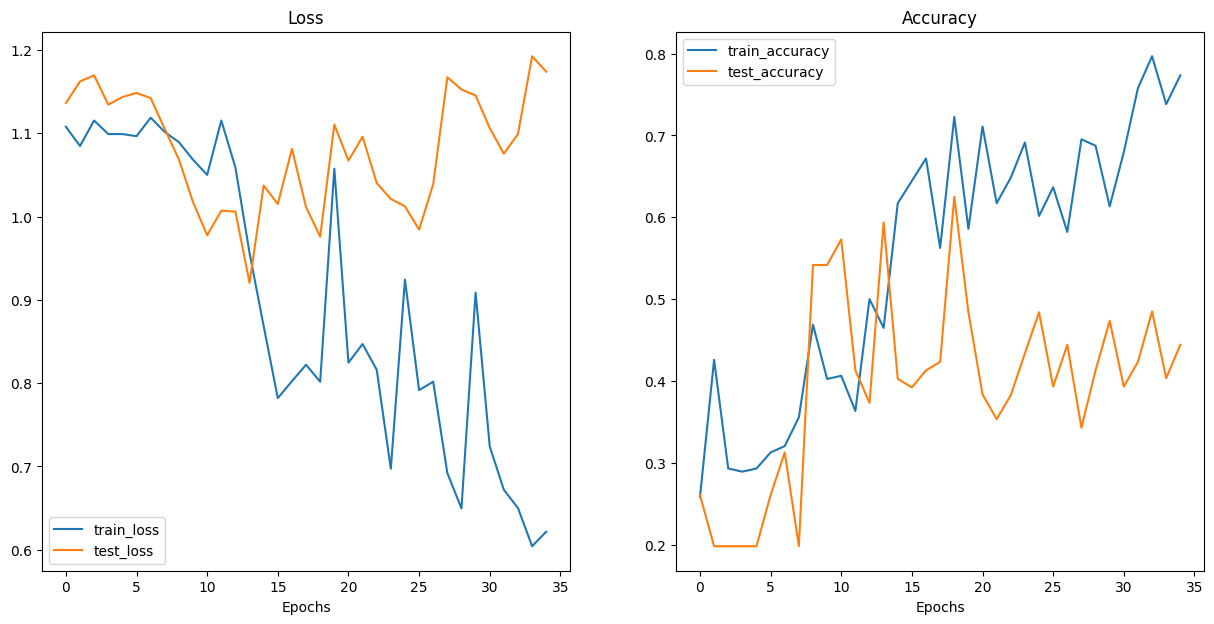

In [17]:
plot_loss_curves(model_0_results)

# Model 1: TinyVGG with Data Augmentation

In [18]:
# Create training transform with TrivialAugment
train_transform_trivial_augment = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor() 
])

# Create testing transform (no data augmentation)
test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

## Create train and test Dataset's and DataLoader's

In [19]:
# Turn image folders into Datasets
train_data_augmented = datasets.ImageFolder(train_dir, transform=train_transform_trivial_augment)
test_data_simple = datasets.ImageFolder(test_dir, transform=test_transform)

train_data_augmented, test_data_simple

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=None)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                ToTensor()
            ))

In [21]:
# Turn Datasets into DataLoader's
import os
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

torch.manual_seed(42)
train_dataloader_augmented = DataLoader(train_data_augmented, 
                                        batch_size=BATCH_SIZE, 
                                        shuffle=True,
                                        num_workers=NUM_WORKERS)

test_dataloader_simple = DataLoader(test_data_simple, 
                                    batch_size=BATCH_SIZE, 
                                    shuffle=False, 
                                    num_workers=NUM_WORKERS)

train_dataloader_augmented, test_dataloader_simple

(<torch.utils.data.dataloader.DataLoader at 0x78f9df7ed810>,
 <torch.utils.data.dataloader.DataLoader at 0x78f9e447a450>)

## Construct and train Model 1

In [22]:
# Create model_1 and send it to the target device
torch.manual_seed(42)
model_1 = TinyVGG(
    input_shape=3,
    hidden_units=10,
    output_shape=len(train_data_augmented.classes)).to(device)
model_1

TinyVGG(
  (conv_block_01): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_02): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)

In [31]:
# Set random seeds
torch.manual_seed(42) 
torch.cuda.manual_seed(42)

# Set number of epochs
NUM_EPOCHS = 35

# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_1.parameters(), lr=0.001)

# Start the timer
from timeit import default_timer as timer 
start_time = timer()

# Train model_1
model_1_results = train(model=model_1, 
                        train_dataloader=train_dataloader_augmented,
                        test_dataloader=test_dataloader_simple,
                        optimizer=optimizer,
                        loss_fn=loss_fn, 
                        epochs=NUM_EPOCHS)

# End the timer and print out how long it took
end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/35 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.9414 | train_acc: 0.4648 | test_loss: 0.9981 | test_acc: 0.3930
Epoch: 2 | train_loss: 1.0036 | train_acc: 0.4766 | test_loss: 1.0402 | test_acc: 0.3731
Epoch: 3 | train_loss: 0.8578 | train_acc: 0.6016 | test_loss: 1.0562 | test_acc: 0.3835
Epoch: 4 | train_loss: 0.8638 | train_acc: 0.5859 | test_loss: 1.0390 | test_acc: 0.3627
Epoch: 5 | train_loss: 0.8598 | train_acc: 0.6445 | test_loss: 1.0709 | test_acc: 0.3722
Epoch: 6 | train_loss: 0.8609 | train_acc: 0.6250 | test_loss: 0.9985 | test_acc: 0.3939
Epoch: 7 | train_loss: 0.7973 | train_acc: 0.6680 | test_loss: 0.9788 | test_acc: 0.3731
Epoch: 8 | train_loss: 0.8575 | train_acc: 0.5156 | test_loss: 0.9761 | test_acc: 0.3930
Epoch: 9 | train_loss: 0.9649 | train_acc: 0.4766 | test_loss: 1.0170 | test_acc: 0.3731
Epoch: 10 | train_loss: 0.8257 | train_acc: 0.6445 | test_loss: 0.9418 | test_acc: 0.4735
Epoch: 11 | train_loss: 0.8638 | train_acc: 0.6484 | test_loss: 0.9668 | test_acc: 0.3939
Epoch: 12 | train_l

## Plot the loss curves of Model 1

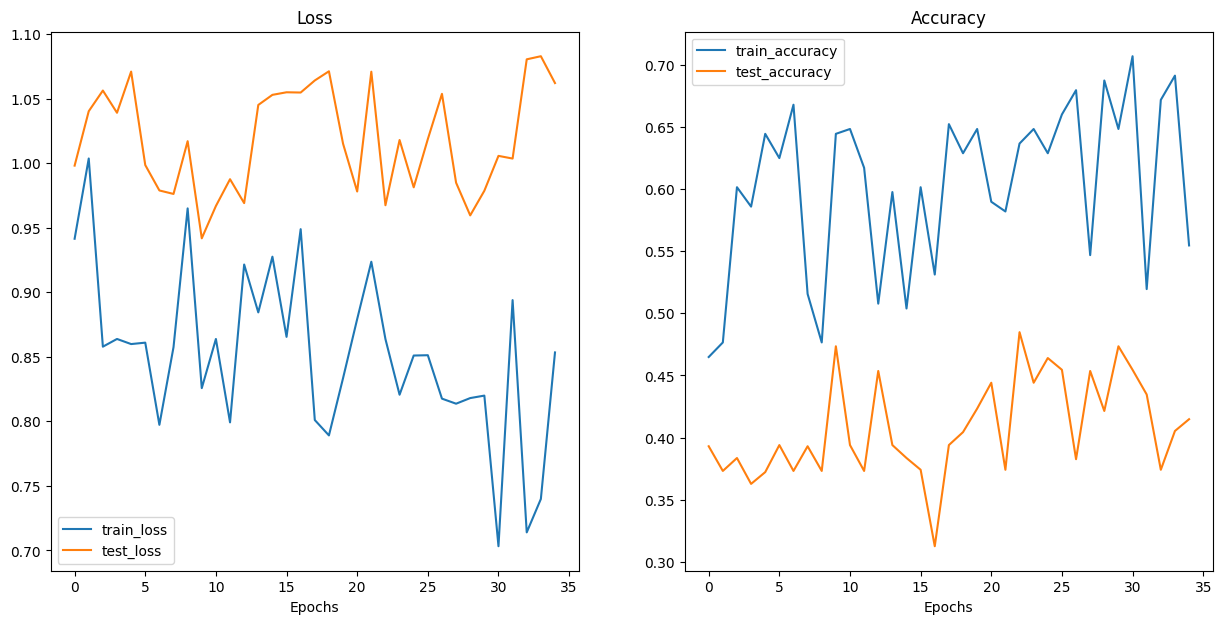

In [32]:
plot_loss_curves(model_1_results)

## Compare model results

In [33]:
import pandas as pd
model_0_df = pd.DataFrame(model_0_results)
model_1_df = pd.DataFrame(model_1_results)
model_0_df

,train_loss,train_acc,test_loss,test_acc
0,1.107836,0.257812,1.136208,0.260417
1,1.084645,0.425781,1.162171,0.197917
2,1.115261,0.292969,1.169489,0.197917
3,1.099015,0.289062,1.134302,0.197917
4,1.098966,0.292969,1.143425,0.197917
5,1.096448,0.312500,1.148283,0.260417
6,1.118668,0.320312,1.142247,0.312500
7,1.101516,0.355469,1.105059,0.197917
8,1.089288,0.468750,1.068583,0.541667
9,1.068184,0.402344,1.017228,0.541667


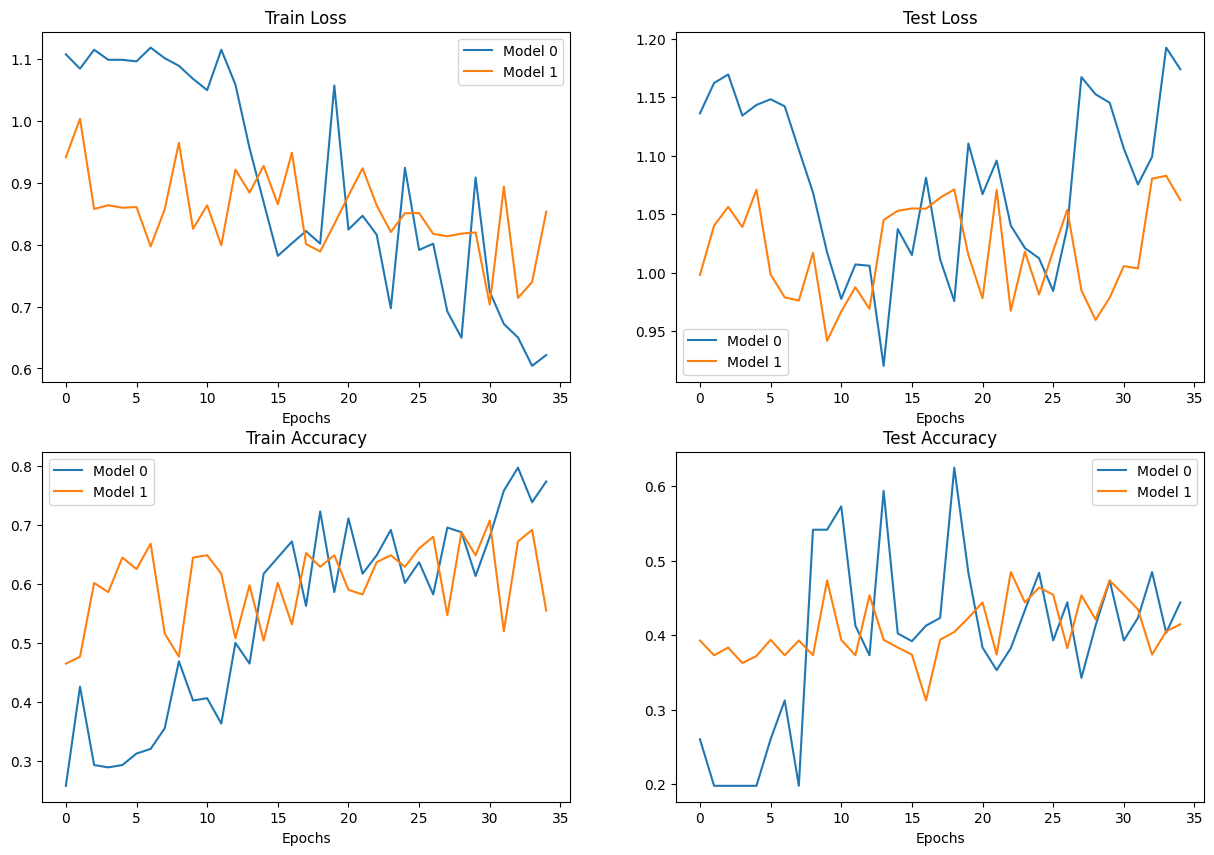

In [34]:
# Setup a plot 
plt.figure(figsize=(15, 10))

# Get number of epochs
epochs = range(len(model_0_df))

# Plot train loss
plt.subplot(2, 2, 1)
plt.plot(epochs, model_0_df["train_loss"], label="Model 0")
plt.plot(epochs, model_1_df["train_loss"], label="Model 1")
plt.title("Train Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot test loss
plt.subplot(2, 2, 2)
plt.plot(epochs, model_0_df["test_loss"], label="Model 0")
plt.plot(epochs, model_1_df["test_loss"], label="Model 1")
plt.title("Test Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot train accuracy
plt.subplot(2, 2, 3)
plt.plot(epochs, model_0_df["train_acc"], label="Model 0")
plt.plot(epochs, model_1_df["train_acc"], label="Model 1")
plt.title("Train Accuracy")
plt.xlabel("Epochs")
plt.legend()

# Plot test accuracy
plt.subplot(2, 2, 4)
plt.plot(epochs, model_0_df["test_acc"], label="Model 0")
plt.plot(epochs, model_1_df["test_acc"], label="Model 1")
plt.title("Test Accuracy")
plt.xlabel("Epochs")
plt.legend();

## Make a prediction on a custom image

In [36]:
# Download custom image
import requests

# Setup custom image path
custom_image_path = image_path / "pizza-dad.jpeg"

# Download the image if it doesn't already exist
if not custom_image_path.is_file():
    with open(custom_image_path, "wb") as f:
        # When downloading from GitHub, need to use the "raw" file link
        request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/04-pizza-dad.jpeg")
        print(f"Downloading {custom_image_path}...")
        f.write(request.content)
else:
    print(f"{custom_image_path} already exists, skipping download.")

data/pizza_steak_sushi/pizza-dad.jpeg already exists, skipping download.


## Loading in a custom image with PyTorch

In [37]:
import torchvision

# Read in custom image
custom_image_uint8 = torchvision.io.read_image(str(custom_image_path))

# Print out image data
print(f"Custom image tensor:\n{custom_image_uint8}\n")
print(f"Custom image shape: {custom_image_uint8.shape}\n")
print(f"Custom image dtype: {custom_image_uint8.dtype}")

Custom image tensor:
tensor([[[154, 173, 181,  ...,  21,  18,  14],
         [146, 165, 181,  ...,  21,  18,  15],
         [124, 146, 172,  ...,  18,  17,  15],
         ...,
         [ 72,  59,  45,  ..., 152, 150, 148],
         [ 64,  55,  41,  ..., 150, 147, 144],
         [ 64,  60,  46,  ..., 149, 146, 143]],

        [[171, 190, 193,  ...,  22,  19,  15],
         [163, 182, 193,  ...,  22,  19,  16],
         [141, 163, 184,  ...,  19,  18,  16],
         ...,
         [ 55,  42,  28,  ..., 107, 104, 103],
         [ 47,  38,  24,  ..., 108, 104, 102],
         [ 47,  43,  29,  ..., 107, 104, 101]],

        [[119, 138, 147,  ...,  17,  14,  10],
         [111, 130, 145,  ...,  17,  14,  11],
         [ 87, 111, 136,  ...,  14,  13,  11],
         ...,
         [ 35,  22,   8,  ...,  52,  52,  48],
         [ 27,  18,   4,  ...,  50,  49,  44],
         [ 27,  23,   9,  ...,  49,  46,  43]]], dtype=torch.uint8)

Custom image shape: torch.Size([3, 4032, 3024])

Custom image dty

In [38]:
# Load in custom image and convert the tensor values to float32
custom_image = torchvision.io.read_image(str(custom_image_path)).type(torch.float32)

# Divide the image pixel values by 255 to get them between [0, 1]
custom_image = custom_image / 255. 

# Print out image data
print(f"Custom image tensor:\n{custom_image}\n")
print(f"Custom image shape: {custom_image.shape}\n")
print(f"Custom image dtype: {custom_image.dtype}")

Custom image tensor:
tensor([[[0.6039, 0.6784, 0.7098,  ..., 0.0824, 0.0706, 0.0549],
         [0.5725, 0.6471, 0.7098,  ..., 0.0824, 0.0706, 0.0588],
         [0.4863, 0.5725, 0.6745,  ..., 0.0706, 0.0667, 0.0588],
         ...,
         [0.2824, 0.2314, 0.1765,  ..., 0.5961, 0.5882, 0.5804],
         [0.2510, 0.2157, 0.1608,  ..., 0.5882, 0.5765, 0.5647],
         [0.2510, 0.2353, 0.1804,  ..., 0.5843, 0.5725, 0.5608]],

        [[0.6706, 0.7451, 0.7569,  ..., 0.0863, 0.0745, 0.0588],
         [0.6392, 0.7137, 0.7569,  ..., 0.0863, 0.0745, 0.0627],
         [0.5529, 0.6392, 0.7216,  ..., 0.0745, 0.0706, 0.0627],
         ...,
         [0.2157, 0.1647, 0.1098,  ..., 0.4196, 0.4078, 0.4039],
         [0.1843, 0.1490, 0.0941,  ..., 0.4235, 0.4078, 0.4000],
         [0.1843, 0.1686, 0.1137,  ..., 0.4196, 0.4078, 0.3961]],

        [[0.4667, 0.5412, 0.5765,  ..., 0.0667, 0.0549, 0.0392],
         [0.4353, 0.5098, 0.5686,  ..., 0.0667, 0.0549, 0.0431],
         [0.3412, 0.4353, 0.5333,  ..

## Predicting on custom images with a trained PyTorch model

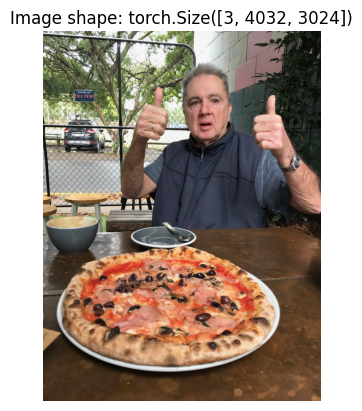

In [39]:
# Plot custom image
plt.imshow(custom_image.permute(1, 2, 0)) # need to permute image dimensions from CHW -> HWC otherwise matplotlib will error
plt.title(f"Image shape: {custom_image.shape}")
plt.axis(False);

In [40]:
# Create transform pipleine to resize image
custom_image_transform = transforms.Compose([
    transforms.Resize((64, 64)),
])

# Transform target image
custom_image_transformed = custom_image_transform(custom_image)

# Print out original shape and new shape
print(f"Original shape: {custom_image.shape}")
print(f"New shape: {custom_image_transformed.shape}")

Original shape: torch.Size([3, 4032, 3024])
New shape: torch.Size([3, 64, 64])


In [45]:
model_1.eval()
with torch.inference_mode():
    # Add an extra dimension to image
    custom_image_transformed_with_batch_size = custom_image_transformed.unsqueeze(dim=0)
    
    # Print out different shapes
    print(f"Custom image transformed shape: {custom_image_transformed.shape}")
    print(f"Unsqueezed custom image shape: {custom_image_transformed_with_batch_size.shape}")
    
    # Make a prediction on image with an extra dimension
    custom_image_pred = model_1(custom_image_transformed.unsqueeze(dim=0).to(device))

Custom image transformed shape: torch.Size([3, 64, 64])
Unsqueezed custom image shape: torch.Size([1, 3, 64, 64])


In [47]:
custom_image_pred, custom_image_pred.shape

(tensor([[ 0.2046, -1.9253, -1.1146]]), torch.Size([1, 3]))

In [ ]:
# Print out prediction logits
print(f"Prediction logits: {custom_image_pred}")

# Convert logits -> prediction probabilities (using torch.softmax() for multi-class classification)
custom_image_pred_probs = torch.softmax(custom_image_pred, dim=1)
print(f"Prediction probabilities: {custom_image_pred_probs}")

# Convert prediction probabilities -> prediction labels
custom_image_pred_label = torch.argmax(custom_image_pred_probs, dim=1)

print(f"Prediction label: {custom_image_pred_label}")

Prediction logits: tensor([[ 0.2046, -1.9253, -1.1146]])
Prediction probabilities: tensor([[0.7214, 0.0857, 0.1929]])
Prediction label: tensor([0])


In [51]:
# Defining the list of classes
class_names = train_data_augmented.classes

print(f"List of images: {class_names}")

# Find the predicted label
custom_image_pred_class = class_names[custom_image_pred_label.cpu()] # put pred label to CPU, otherwise will error
print(f"Predicted class: {custom_image_pred_class}")

List of images: ['pizza', 'steak', 'sushi']
Predicted class: pizza


In [53]:
def pred_and_plot_image(model: torch.nn.Module, 
                        image_path: str, 
                        class_names: List[str] = None, 
                        transform=None,
                        device: torch.device = device):
    """Makes a prediction on a target image and plots the image with its prediction."""
    
    # 1. Load in image and convert the tensor values to float32
    target_image = torchvision.io.read_image(str(image_path)).type(torch.float32)
    
    # 2. Divide the image pixel values by 255 to get them between [0, 1]
    target_image = target_image / 255. 
    
    # 3. Transform if necessary
    if transform:
        target_image = transform(target_image)
    
    # 4. Make sure the model is on the target device
    model.to(device)
    
    # 5. Turn on model evaluation mode and inference mode
    model.eval()
    with torch.inference_mode():
        # Add an extra dimension to the image
        target_image = target_image.unsqueeze(dim=0)
    
        # Make a prediction on image with an extra dimension and send it to the target device
        target_image_pred = model(target_image.to(device))
        
    # 6. Convert logits -> prediction probabilities (using torch.softmax() for multi-class classification)
    target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

    # 7. Convert prediction probabilities -> prediction labels
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)
    
    # 8. Plot the image alongside the prediction and prediction probability
    plt.imshow(target_image.squeeze().permute(1, 2, 0)) # make sure it's the right size for matplotlib
    if class_names:
        title = f"Pred: {class_names[target_image_pred_label.cpu()]} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    else: 
        title = f"Pred: {target_image_pred_label} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    plt.title(title)
    plt.axis(False);

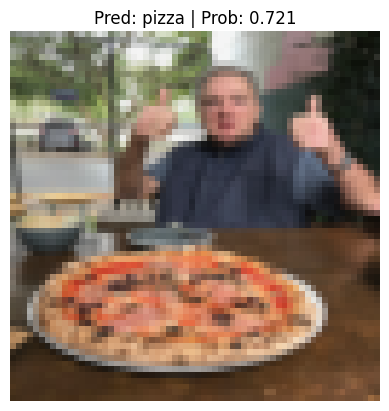

In [54]:
# Pred on our custom image
pred_and_plot_image(model=model_1,
                    image_path=custom_image_path,
                    class_names=class_names,
                    transform=custom_image_transform,
                    device=device)

Selected image: data/pizza_steak_sushi/test/sushi/343036.jpg
True label: sushi


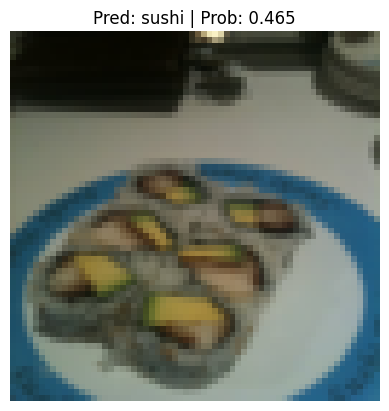

In [56]:
import random
from pathlib import Path

# 1. Set the target folder (usually testing on the test set)
test_dir = image_path / "test"

# 2. Find all image files (*.jpg, *.jpeg, *.png) recursively
# This searches inside test/pizza, test/steak, test/sushi
image_path_list = list(test_dir.glob("*/*.jpg")) + list(test_dir.glob("*/*.jpeg"))

# 3. Pick a random image path from the list
random_image_path = random.choice(image_path_list)

# (Optional) Find the true label from the parent folder's name
true_label = random_image_path.parent.name
print(f"Selected image: {random_image_path}")
print(f"True label: {true_label}")

# 4. Predict and plot on the random image
pred_and_plot_image(model=model_1,
                    image_path=random_image_path,
                    class_names=class_names,
                    transform=custom_image_transform,
                    device=device)

In [59]:
import torch
import torchvision
import matplotlib.pyplot as plt
from pathlib import Path
from typing import List

def pred_and_plot_image_all_probs(model: torch.nn.Module, 
                                  image_path: str, 
                                  class_names: List[str] = None, 
                                  transform=None,
                                  device: torch.device = device):
    """
    Makes a prediction on a target image and plots:
    1. The image with its predicted & true label.
    2. A horizontal bar chart displaying all class probabilities.
    """
    # 1. Load image and scale pixels to [0, 1]
    target_image = torchvision.io.read_image(str(image_path)).type(torch.float32) / 255.0
    
    # 2. Apply transform if given
    if transform:
        target_image = transform(target_image)
        
    # 3. Model inference
    model.to(device)
    model.eval()
    with torch.inference_mode():
        # Add batch dimension: [C, H, W] -> [1, C, H, W]
        target_image_batch = target_image.unsqueeze(dim=0).to(device)
        target_image_pred = model(target_image_batch)
        
    # 4. Convert logits -> probabilities
    target_image_pred_probs = torch.softmax(target_image_pred, dim=1).squeeze().cpu()
    target_image_pred_label = torch.argmax(target_image_pred_probs).item()
    
    # 5. Extract class names & true label from directory
    classes = class_names if class_names else [f"Class {i}" for i in range(len(target_image_pred_probs))]
    true_label = Path(image_path).parent.name
    pred_label = classes[target_image_pred_label]
    probs = target_image_pred_probs.numpy()
    
    # 6. Setup 1x2 subplot figure
    plt.figure(figsize=(10, 4))
    
    # --- SUBPLOT 1: The Image ---
    plt.subplot(1, 2, 1)
    # Permute from [C, H, W] to [H, W, C] for imshow
    plt.imshow(target_image.cpu().permute(1, 2, 0))
    title_color = "green" if pred_label == true_label else "red"
    plt.title(f"Pred: {pred_label} ({probs[target_image_pred_label]*100:.1f}%)\nTrue: {true_label}", 
              color=title_color, fontsize=12, fontweight="bold")
    plt.axis(False)
    
    # --- SUBPLOT 2: Horizontal Bar Chart of All Probabilities ---
    plt.subplot(1, 2, 2)
    bars = plt.barh(classes, probs, color="skyblue")
    
    # Highlight the predicted class in green
    bars[target_image_pred_label].set_color("mediumseagreen")
    
    # Display exact percentage numbers next to each bar
    for bar in bars:
        w = bar.get_width()
        plt.text(w + 0.02, bar.get_y() + bar.get_height() / 2, f"{w * 100:.1f}%", 
                 va="center", fontsize=10, fontweight="bold")
                 
    plt.xlim(0, 1.15)
    plt.xlabel("Probability")
    plt.title("All Prediction Probabilities", fontsize=12)
    plt.tight_layout()
    plt.show()
    
    # Also print breakdown to console
    print(f"Image: {Path(image_path).name}")
    for c, p in zip(classes, probs):
        print(f"{c:7s}: {p*100:5.2f}%")

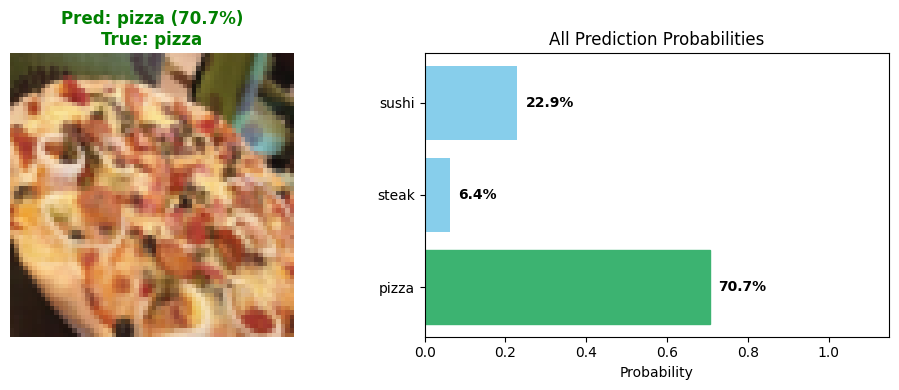

Image: 1503858.jpg
pizza  : 70.71%
steak  :  6.36%
sushi  : 22.93%


In [65]:
import random
from pathlib import Path

# 1. Grab all images from the test directory
test_dir = image_path / "test"
image_path_list = list(test_dir.glob("*/*.jpg")) + list(test_dir.glob("*/*.jpeg"))

# 2. Pick a random image path
random_image_path = random.choice(image_path_list)

# 3. Predict, plot image, and visualize all probabilities
pred_and_plot_image_all_probs(model=model_1,
                              image_path=random_image_path,
                              class_names=class_names,
                              transform=custom_image_transform,
                              device=device)